# Лабораторная работа № 2
## Построение базовой ML-модели и проверка устойчивости входных данных

**Дисциплина:** Киберустойчивость систем искусственного интеллекта  
**Выполнил:** Серко Сергей Игоревич, группа N4270  
**Направление:** Computer Vision — классификация рукописных цифр

**Цель работы:** обучить базовую модель на данных лабораторной работы № 1, оценить качество распознавания, реализовать проверку входных данных и исследовать чувствительность модели к небольшим искажениям изображений.

**Задачи исследования:** подготовка и контроль целостности данных; воспроизводимое разделение выборки; обучение и оценка классификатора; реализация единого интерфейса предсказания; автоматическое тестирование; эксперимент с шумом, изменением яркости и нетипичным входом; проверка безопасности кода и сохранение результатов.

## 1. Характеристики программной среды

Исследование выполнено на Ubuntu с использованием Python 3.12, библиотек NumPy, pandas и scikit-learn. Исходные данные, программы обучения и модули проверки входов объединены в проект `ml-project`. Ниже определяются рабочий каталог и версии основных библиотек, от которых зависит воспроизводимость вычислений.

In [1]:
from pathlib import Path
import json
from contextlib import redirect_stdout
from io import StringIO
import platform
import sys

import numpy as np
import pandas as pd
import sklearn
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir() and (ROOT / "data").is_dir(), "Проект ЛР №1 не найден"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Рабочий каталог проекта:", ROOT)
print("Версия Python:", platform.python_version())
print("NumPy:", np.__version__, "Pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)
print("Пользователь:", __import__("getpass").getuser())

Рабочий каталог проекта: /home/mluser/ml-project
Версия Python: 3.12.3
NumPy: 2.5.4 Pandas: 3.1.0 scikit-learn: 1.9.1
Пользователь: mluser


## 2. Контроль целостности и анализ исходных данных

Используется набор **Optical Recognition of Handwritten Digits** из лабораторной работы № 1. Исходная подвыборка `digits_original.csv` содержит 1797 изображений. Сбалансированный набор `digits.csv` состоит из **1740 объектов** — по 174 изображения каждой цифры от 0 до 9. Каждый объект представлен 64 интенсивностями пикселей изображения размером **8 × 8**; столбец `target` содержит метку класса.

Перед обработкой выполняется сравнение контрольных сумм **SHA256** с зафиксированными значениями. Затем проверяются типы признаков, пропущенные и бесконечные значения, дубликаты строк и изображений, допустимый диапазон интенсивностей `[0; 16]` и метки классов. При несоответствии проверка прерывается, что исключает неявную замену исходных данных.

In [2]:
from src.data import load_and_check_data, verify_lab1_data

verified_hashes = verify_lab1_data()
for filename, sha in verified_hashes.items():
    print(f"SHA256 проверен: {filename}: {sha}")
X, y, checks = load_and_check_data()

print("Размер матрицы признаков:", X.shape)
print("Число меток:", y.shape[0])
print("Пропущенных значений:", checks["missing_total"])
print("Полных дублей:", checks["duplicate_complete_rows"])
print("Дублей признаков:", checks["duplicate_feature_vectors"])
print("Исключено на этапе ЛР №2:", checks["rows_removed_in_lab2"])

classes = pd.DataFrame({
    "Класс": list(range(10)),
    "Исходный датасет": [checks["original_class_counts"][str(i)] for i in range(10)],
    "Сбалансированный": [checks["classes"][str(i)] for i in range(10)],
})
display(classes)

SHA256 проверен: data/digits_original.csv: 59834b81e5525fe3152c7416217c7790c2213c0da554e89ae96dddef27b35bda
SHA256 проверен: data/digits.csv: 4b55658bf1299c5e4bdce02ae154081e2694f74e22eca2c5bc8b7a5c8d67419e
Размер матрицы признаков: (1740, 64)
Число меток: 1740
Пропущенных значений: 0
Полных дублей: 0
Дублей признаков: 0
Исключено на этапе ЛР №2: 0


,Класс,Исходный датасет,Сбалансированный
0,0,178,174
1,1,182,174
2,2,177,174
3,3,183,174
4,4,181,174
5,5,182,174
6,6,181,174
7,7,179,174
8,8,174,174
9,9,180,174


### Результат анализа данных

Проверка не выявила пропусков, некорректных значений пикселей и полных дубликатов. Распределение рабочего набора строго равномерное: **174 объекта каждого из 10 классов**. На данном этапе дополнительные строки не исключались и пропуски не заполнялись.

Объём позволяет провести эксперимент на CPU с отдельной тестовой частью, но **не подтверждает применимость модели к произвольным рукописным документам**. Датасет состоит из предварительно нормализованных изображений низкого разрешения. Идентификаторы авторов и серий отсутствуют; поэтому возможность разделения по авторам исходных цифр отдельно не проверяется.

## 3. Разделение на обучающую и тестовую выборки

Выборка разделяется с параметрами `test_size=0.2`, `random_state=42` и `stratify=y`. В обучающую часть входят **1392 изображения**, в тестовую — **348**. Стратификация сохраняет близкие доли всех десяти классов.

Контролируются отсутствие пересечения индексов и совпадающих векторов изображений между выборками. Тестовая часть используется только для итоговой оценки: параметры масштабирования рассчитываются по обучающим данным.

In [3]:
from src.data import split_data

train_idx, test_idx = split_data(X, y)
print("Обучающих изображений:", len(train_idx))
print("Тестовых изображений:", len(test_idx))
print("Пересечение индексов:", len(set(train_idx) & set(test_idx)))
assert not (set(train_idx) & set(test_idx))

display(pd.DataFrame({
    "Цифра": range(10),
    "Train": np.bincount(y[train_idx], minlength=10),
    "Test": np.bincount(y[test_idx], minlength=10),
}))

Обучающих изображений: 1392
Тестовых изображений: 348
Пересечение индексов: 0


,Цифра,Train,Test
0,0,139,35
1,1,140,34
2,2,139,35
3,3,139,35
4,4,139,35
5,5,139,35
6,6,139,35
7,7,139,35
8,8,140,34
9,9,139,35


## 4. Обучение базовой модели

В качестве классификатора выбрана **логистическая регрессия** (`LogisticRegression`). Это линейная модель, подходящая для небольших изображений, представленных числовыми признаками. Она обучается за короткое время на CPU и служит воспроизводимым базовым ориентиром для дальнейших экспериментов.

Предобработка и классификация объединены в `Pipeline(StandardScaler(), LogisticRegression(...))`. Масштабирование вычисляется только при обучении конвейера на `X_train` и автоматически применяется к новым данным. Параметры модели зафиксированы: `C=1.0`, `solver='lbfgs'`, `max_iter=2000`, `random_state=42`.

Для сравнения используется **DummyClassifier**, всегда выбирающий наиболее частый класс обучающей выборки. Параметры, время обучения, разбиение, предсказания и метрики сохраняются в файлы проекта.

In [4]:
from src.train import run_training

with redirect_stdout(StringIO()):
    baseline = run_training()
print("Основная метрика (Accuracy):", round(baseline["accuracy"], 6))
print("Macro-F1:", round(baseline["f1_macro"], 6))
print("Accuracy самого частого класса:", round(baseline["reference_majority_accuracy"], 6))
print("Ошибочных ответов:", baseline["wrong_predictions"])
print("Верно классифицировано:", baseline["n_test"] - baseline["wrong_predictions"], "из", baseline["n_test"])
print("Превышение точности простого ориентира:",
      round((baseline["accuracy"] - baseline["reference_majority_accuracy"]) * 100, 2), "п.п.")

Основная метрика (Accuracy): 0.974138
Macro-F1: 0.974022
Accuracy самого частого класса: 0.097701
Ошибочных ответов: 9
Верно классифицировано: 339 из 348
Превышение точности простого ориентира: 87.64 п.п.


## 5. Оценка качества классификации

Качество оценивается **на отложенной тестовой выборке** по метрикам:

- **Accuracy** — доля правильно распознанных изображений;
- **Precision** — доля правильных прогнозов среди всех прогнозов данного класса;
- **Recall** — доля правильно найденных объектов данного класса;
- **F1-score** — гармоническое среднее Precision и Recall.

Для многоклассовой задачи используются усреднения **macro** (равный вес всех классов) и **weighted** (с учётом числа объектов каждого класса). Ниже приведены сводные результаты, метрики по цифрам, матрица ошибок и примеры неправильной классификации.

In [5]:
quality_table = pd.DataFrame([
    {"Метрика": "Accuracy", "Значение": baseline["accuracy"]},
    {"Метрика": "Precision (macro)", "Значение": baseline["precision_macro"]},
    {"Метрика": "Recall (macro)", "Значение": baseline["recall_macro"]},
    {"Метрика": "F1 (macro)", "Значение": baseline["f1_macro"]},
    {"Метрика": "F1 (weighted)", "Значение": baseline["f1_weighted"]},
    {"Метрика": "Baseline самого частого класса", "Значение": baseline["reference_majority_accuracy"]},
])
display(Markdown("**Таблица 1 — Сводные метрики классификатора**"))
display(quality_table.style.format({"Значение":"{:.4f}"}))
by_class = pd.DataFrame.from_dict(baseline["per_class"], orient="index").reset_index()
by_class.columns = ["Цифра", "Precision", "Recall", "F1", "Число в тесте"]
display(Markdown("**Таблица 2 — Метрики качества по классам**"))
display(by_class.round(4))

**Таблица 1 — Сводные метрики классификатора**

,Метрика,Значение
0,Accuracy,0.9741
1,Precision (macro),0.9748
2,Recall (macro),0.9740
3,F1 (macro),0.9740
4,F1 (weighted),0.9742
5,Baseline самого частого класса,0.0977


**Таблица 2 — Метрики качества по классам**

,Цифра,Precision,Recall,F1,Число в тесте
0,0,1.0000,1.0000,1.0000,35
1,1,0.9706,0.9706,0.9706,34
2,2,0.9722,1.0000,0.9859,35
3,3,1.0000,0.9714,0.9855,35
4,4,1.0000,1.0000,1.0000,35
5,5,0.9714,0.9714,0.9714,35
6,6,1.0000,1.0000,1.0000,35
7,7,1.0000,1.0000,1.0000,35
8,8,0.8649,0.9412,0.9014,34
9,9,0.9688,0.8857,0.9254,35


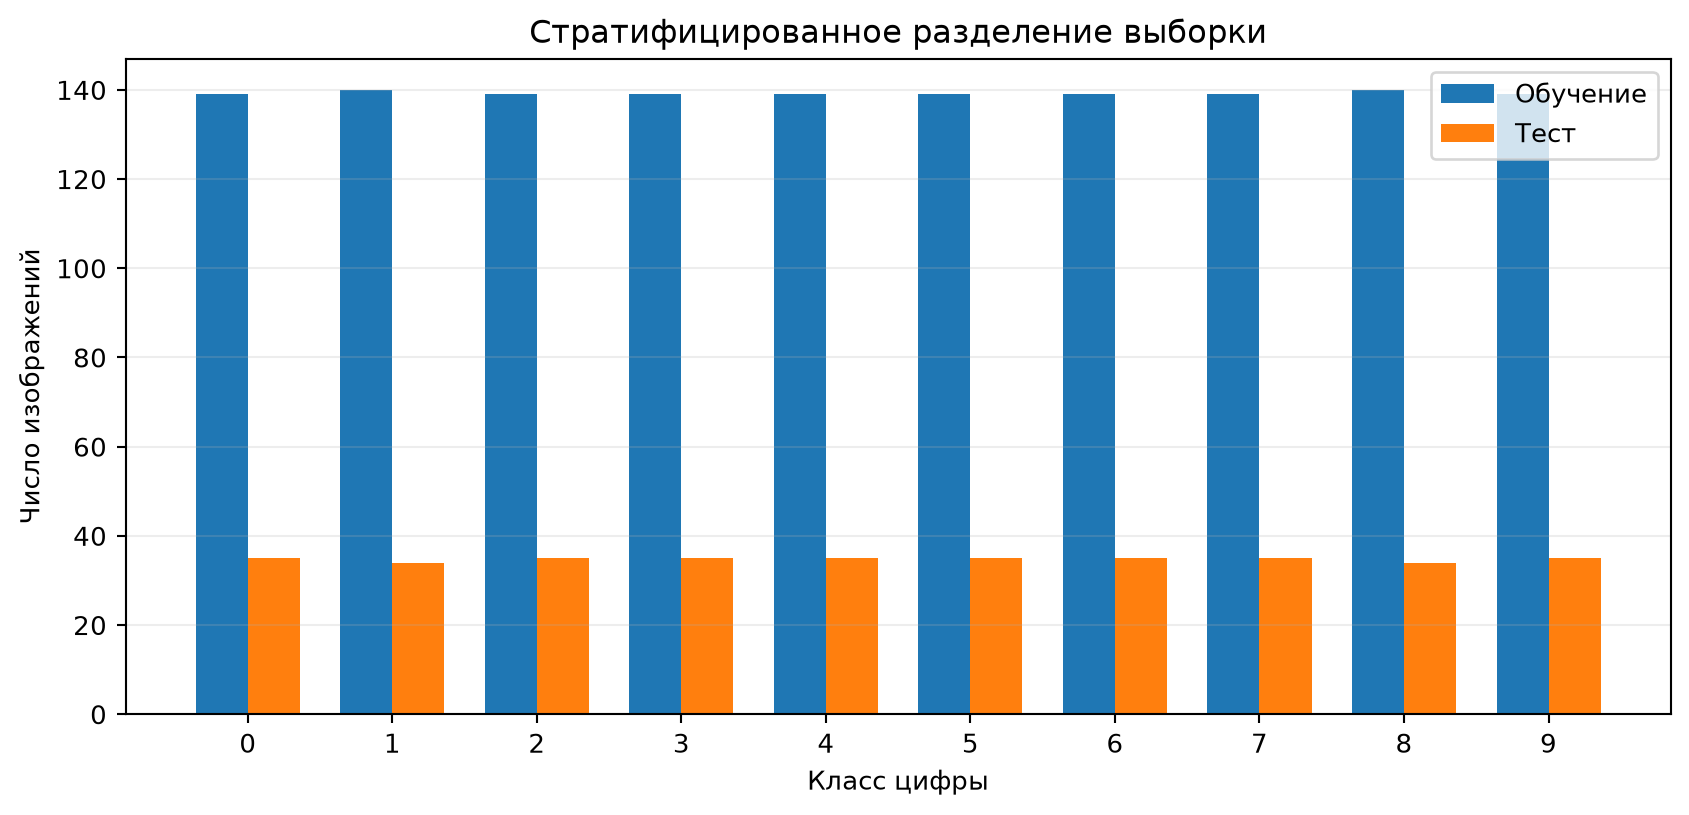

*Рисунок 1 — Распределение классов в обучающей и тестовой выборках*

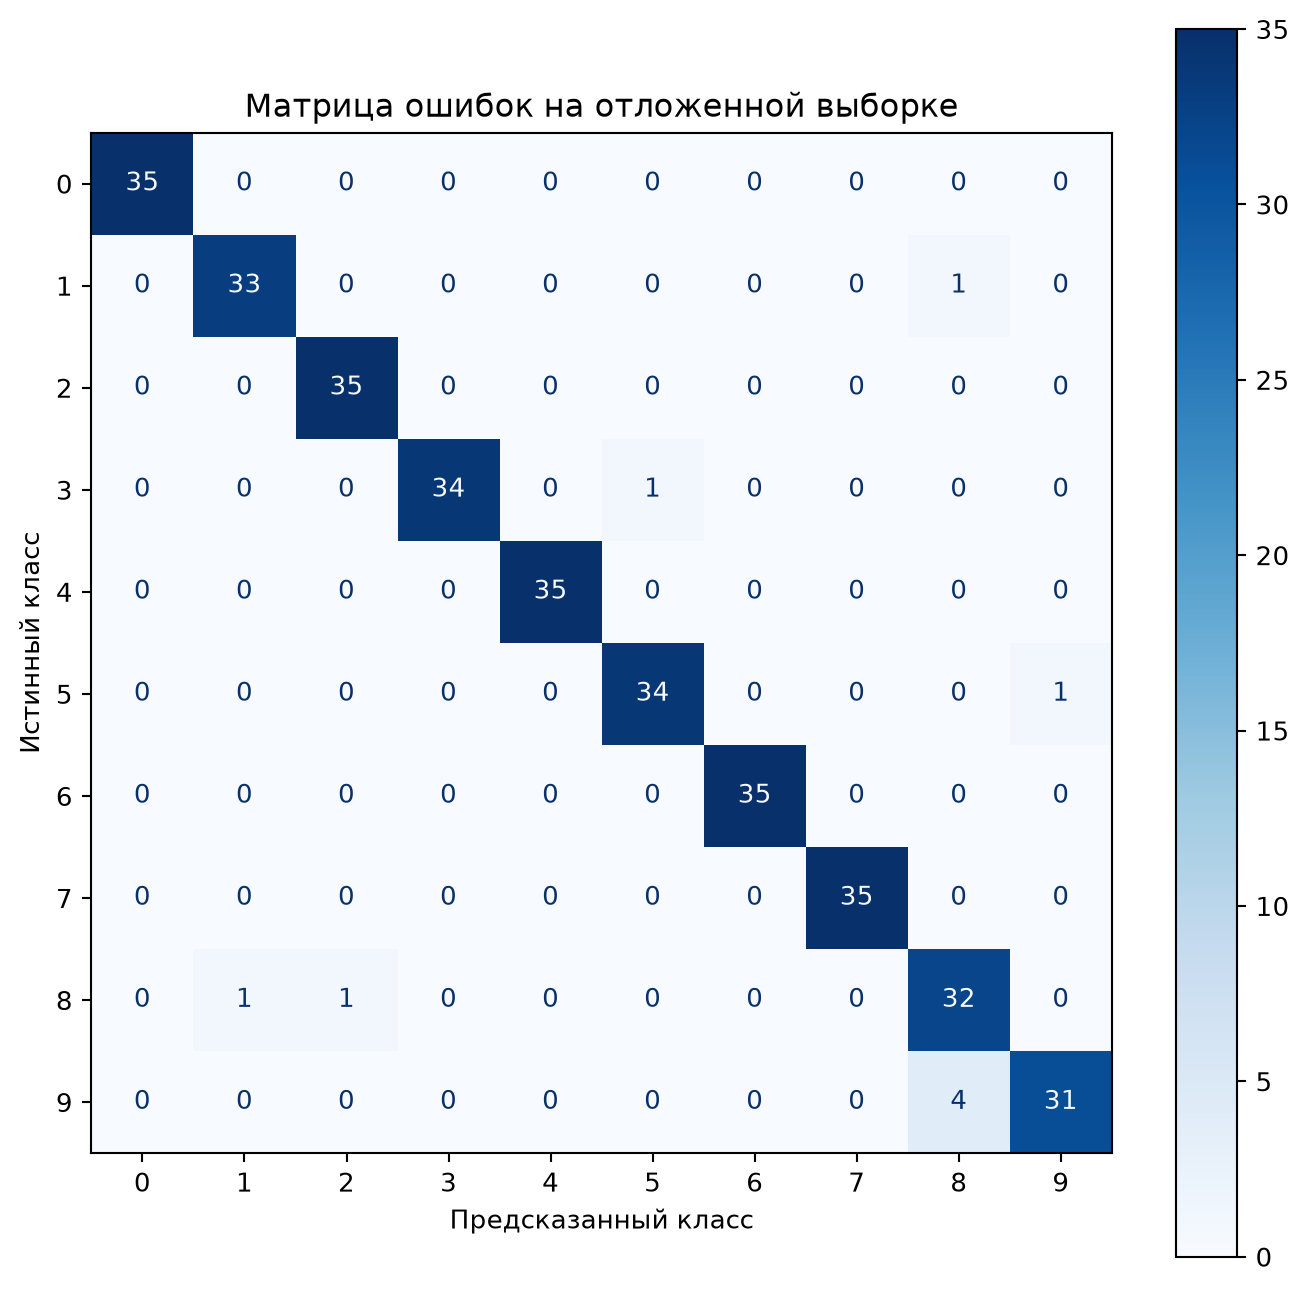

*Рисунок 2 — Матрица ошибок базового классификатора*

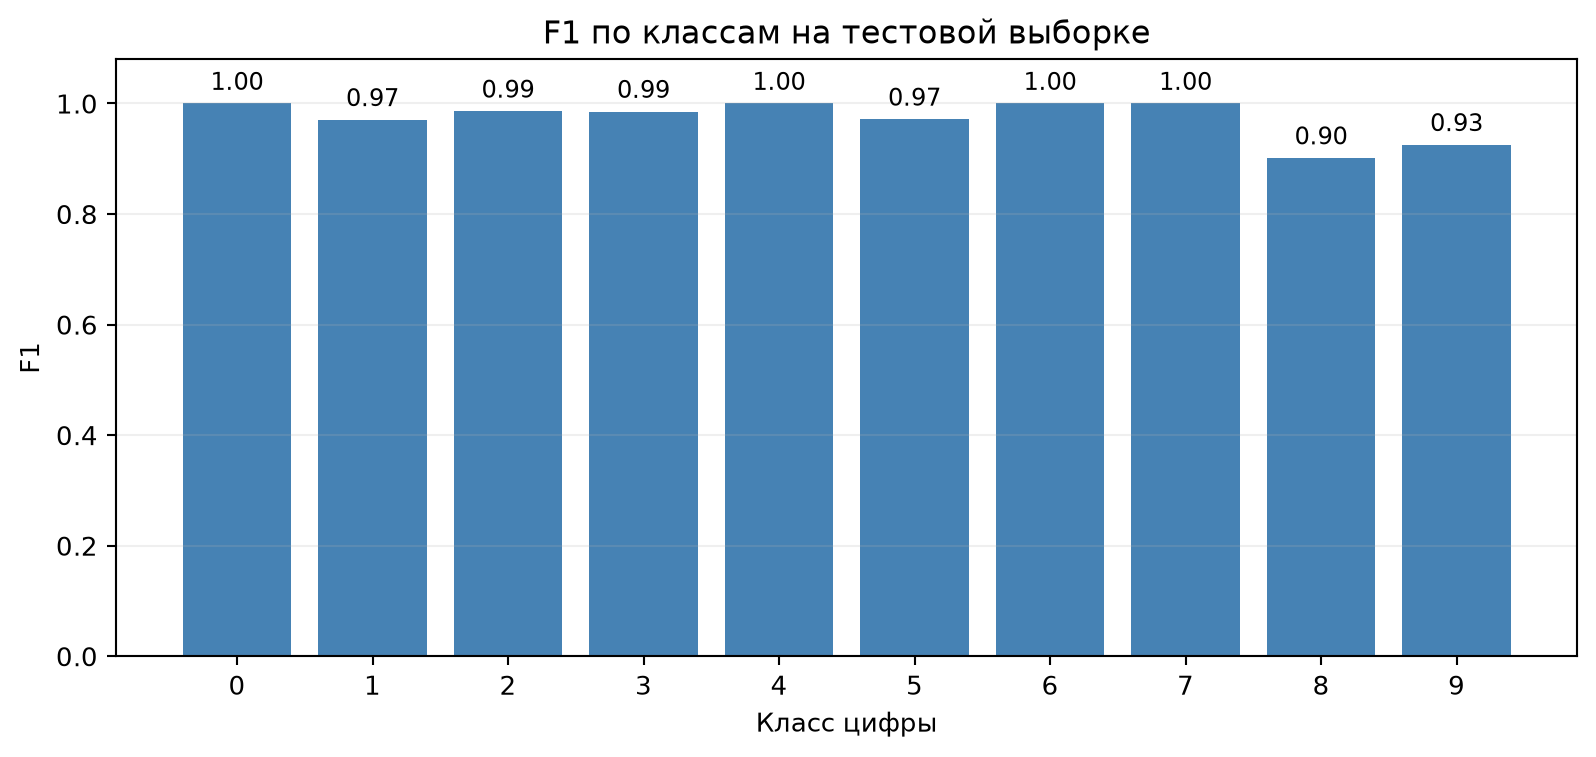

*Рисунок 3 — Значения F1-score для цифр от 0 до 9*

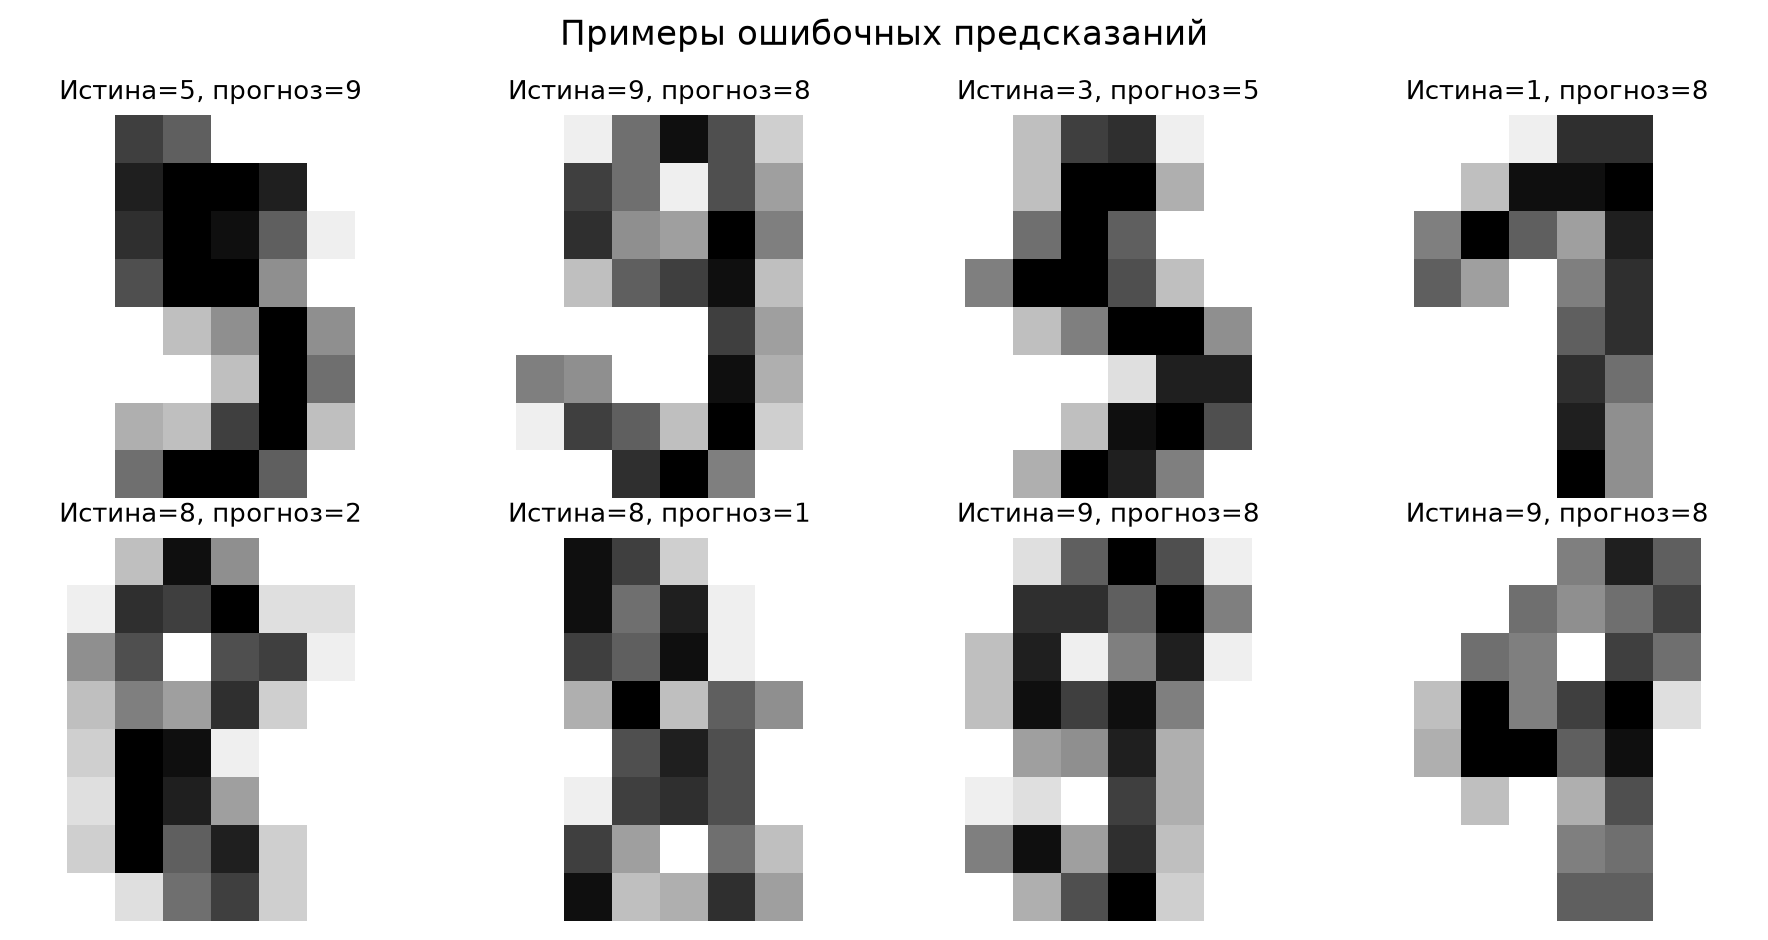

*Рисунок 4 — Примеры изображений, распознанных с ошибкой*

In [6]:
figures = (
    ("lab2_01_class_split.png", "Рисунок 1 — Распределение классов в обучающей и тестовой выборках"),
    ("lab2_02_confusion_matrix.png", "Рисунок 2 — Матрица ошибок базового классификатора"),
    ("lab2_03_f1_by_class.png", "Рисунок 3 — Значения F1-score для цифр от 0 до 9"),
    ("lab2_04_wrong_predictions.png", "Рисунок 4 — Примеры изображений, распознанных с ошибкой"),
)
for filename, title in figures:
    path = ROOT / "reports" / "figures" / filename
    display(Image(filename=str(path)))
    display(Markdown(f"*{title}*"))

## 6. Проверка входных данных и автоматизированное тестирование

Единый интерфейс предсказания реализован в `src/inference.py`. Он принимает изображение **8 × 8**, вектор из **64 чисел** или пакет изображений. До передачи данных классификатору проверяются структура запроса, типы, размерность и допустимые значения.

**Принятая политика обработки входов:**

- допустимый диапазон интенсивностей пикселей — **от 0 до 16 включительно**;
- `NaN`, `Inf`, пустые данные и строки вместо чисел отклоняются;
- максимальный размер одного пакета — **32 изображения**;
- при нарушении ограничений возвращается `InputValidationError`, без обращения к модели.

Лимит пакета ограничивает вычислительную нагрузку при предсказании. Он действует после формирования массива и сам по себе не защищает этап чтения произвольно большого файла; при создании файлового API понадобится отдельное ограничение входного потока и размера декодированных данных.

Таблица ниже содержит **девять негативных сценариев и один положительный** с ожидаемым и фактическим поведением.

In [7]:
from src.validation_cases import run_validation_cases

with redirect_stdout(StringIO()):
    validation_results = run_validation_cases()
validation_table = pd.DataFrame(validation_results["cases"])[[
    "input_description", "expected", "actual", "model_calls", "passed"
]].rename(columns={
    "input_description": "Входной случай",
    "expected": "Ожидаемый результат",
    "actual": "Фактический результат",
    "model_calls": "Вызовов модели",
    "passed": "Успешно"
})
validation_table["Успешно"] = validation_table["Успешно"].map({True: "Да", False: "Нет"})
display(Markdown("**Таблица 3 — Результаты негативных и положительного тестов**"))
display(validation_table)
print("Пройдено тестовых случаев:", validation_results["passed"], "из", validation_results["count"])

**Таблица 3 — Результаты негативных и положительного тестов**

,Входной случай,Ожидаемый результат,Фактический результат,Вызовов модели,Успешно
0,Отсутствует обязательное поле pixels,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Request requires exactly...,0,Да
1,Строка abc вместо значения пикселя,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Pixel data must be numer...,0,Да
2,Неверная форма изображения 7x8,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Expected image shape 8x8...,0,Да
3,Пустой список пикселей,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Empty input is not accepted,0,Да
4,Изображение с NaN,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: NaN and Inf are forbidden,0,Да
5,Изображение с Inf,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: NaN and Inf are forbidden,0,Да
6,Пакет из 33 изображений при максимуме 32,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Input exceeds the maximu...,0,Да
7,Пиксели со значениями 16.1 вне диапазона,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Pixel intensity must be ...,0,Да
8,Бинарные байты вместо декодированного массива,"Контролируемый InputValidationError, 0 вызовов...",InputValidationError: Input must be a NumPy ar...,0,Да
9,Корректный числовой массив 8x8 из нулей,Один прогноз класса 0–9,Предсказан класс 4,1,Да


Пройдено тестовых случаев: 10 из 10


### 6.1. Результаты модульных тестов

Дополнительно используется `pytest` для проверки корректной классификации, обработки ошибочных запросов, лимитов, целостности данных, разбиения выборки и загрузки модели. В отрицательных сценариях отдельно контролируется, что вызов `predict()` не выполнялся. Результат повторного запуска тестов приводится ниже.

In [8]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pytest", "tests/", "-q", "--color=no"],
    cwd=ROOT, capture_output=True, text=True, check=False,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
assert result.returncode == 0, "Тесты не пройдены: проверьте ошибку выше"

.................................                                        [100%]
33 passed in 1.40s



## 7. Эксперимент с небольшими искажениями изображений

Из тестовой выборки с фиксированным `seed=2026` отбираются **20 изображений** — по два примера каждого класса. Для каждого изображения создаются два варианта:

1. **Слабый аддитивный шум:** независимые значения из нормального распределения с `σ=0.8`.
2. **Изменение яркости:** добавление `0.6` к значениям интенсивностей.

После изменения значения пикселей ограничиваются диапазоном `[0; 16]`, а исходные метки сохраняются. Измеряются точность классификации и доля ответов, изменившихся относительно первоначальных прогнозов. Сопоставление выполняется для одних и тех же 20 объектов.

**Таблица 4 — Результаты эксперимента на 20 изображениях**

,Тип входа,Точность,Доля изменившихся ответов,Число изменившихся ответов
0,Без изменений,0.85,0.00,0
1,Шум,0.85,0.10,2
2,Яркость,0.90,0.15,3


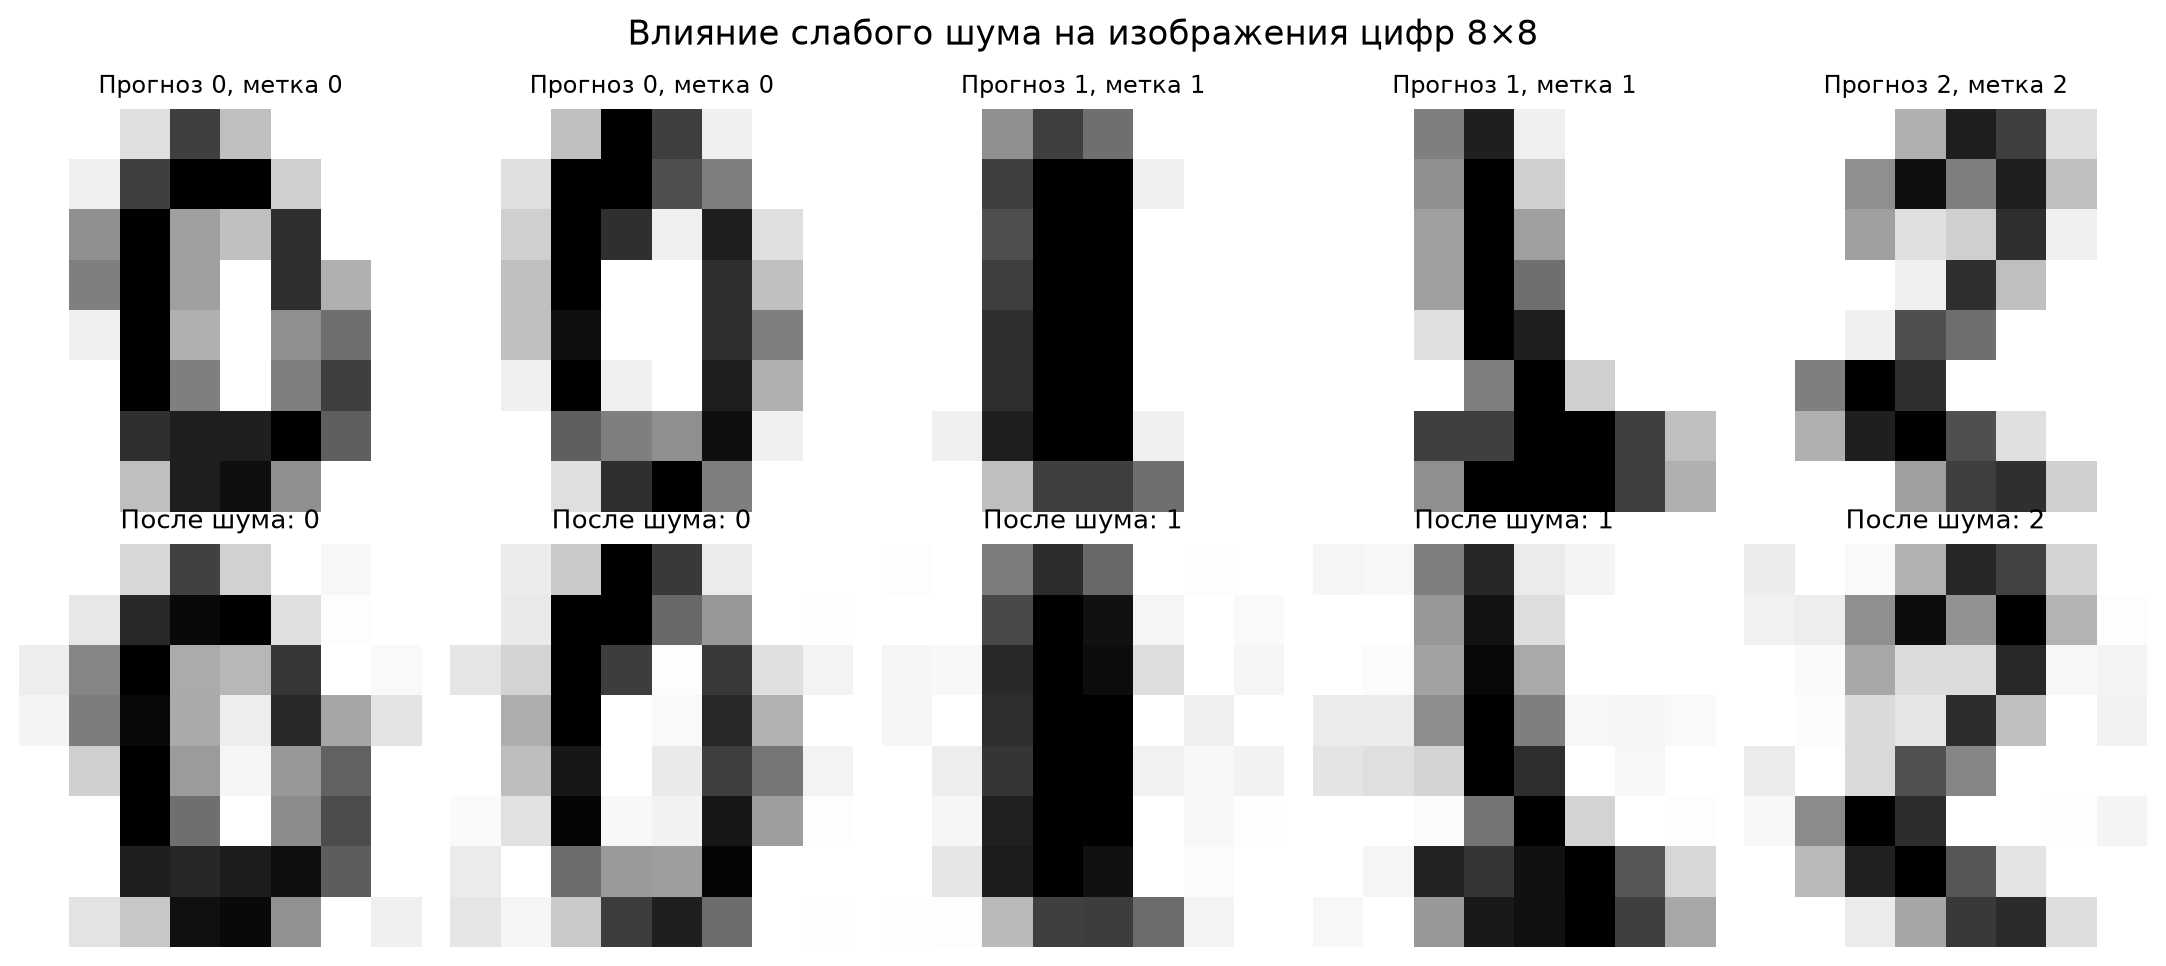

*Рисунок 5 — Исходные и зашумлённые изображения*

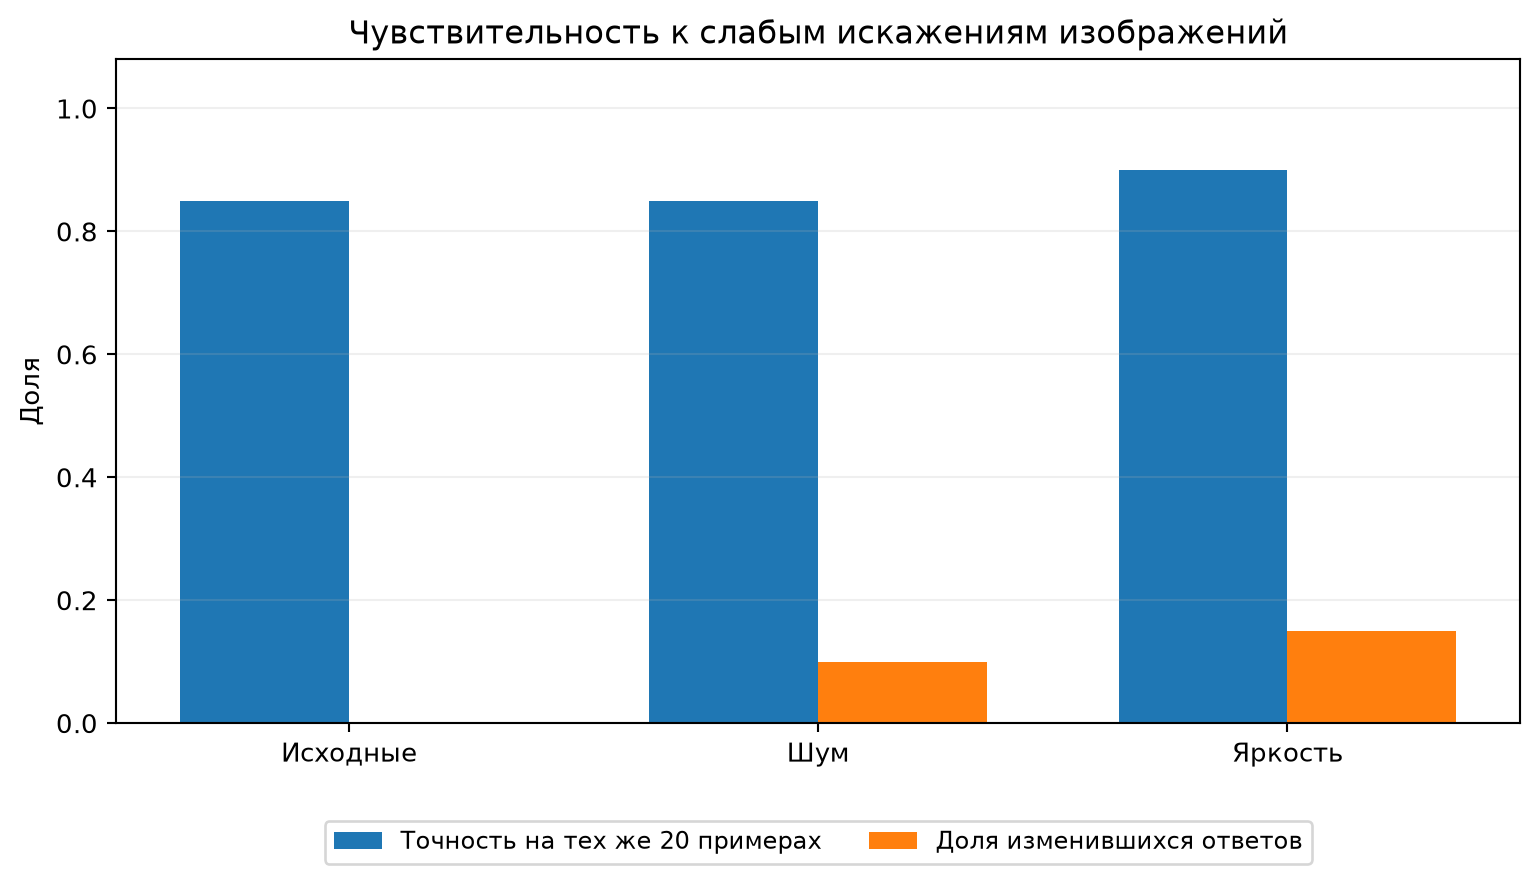

*Рисунок 6 — Изменение точности и ответов при искажениях*

Изменение ответов при шуме: 2 из 20
Изменение ответов при повышении яркости: 3 из 20


In [9]:
from src.robustness import run_robustness

with redirect_stdout(StringIO()):
    robustness = run_robustness()
summary = []
for key, name in [("clean", "Без изменений"), ("noise", "Шум"), ("brightness", "Яркость")]:
    rec = robustness["variants"][key]
    summary.append({"Тип входа": name, "Точность": rec["accuracy"],
                    "Доля изменившихся ответов": rec["changed_fraction"],
                    "Число изменившихся ответов": rec["changed_count"]})
display(Markdown("**Таблица 4 — Результаты эксперимента на 20 изображениях**"))
display(pd.DataFrame(summary))
for filename, title in (
    ("lab2_05_noise_examples.png", "Рисунок 5 — Исходные и зашумлённые изображения"),
    ("lab2_06_robustness.png", "Рисунок 6 — Изменение точности и ответов при искажениях"),
):
    display(Image(filename=str(ROOT / "reports" / "figures" / filename)))
    display(Markdown(f"*{title}*"))

print("Изменение ответов при шуме:", robustness["variants"]["noise"]["changed_count"], "из 20")
print("Изменение ответов при повышении яркости:", robustness["variants"]["brightness"]["changed_count"], "из 20")

## 8. Исследование нетипичного входного изображения

Для отдельной проверки используется матрица **8 × 8**, полностью заполненная значением `16`. Она удовлетворяет формальным требованиям к размеру и интенсивности пикселей, но существенно отличается по структуре от обычных изображений рукописных цифр.

Степень отличия оценивается по **евклидову расстоянию до ближайшего обучающего изображения**. Полученное расстояние сравнивается с 95-м процентилем расстояний от тестовых объектов до обучающей выборки. Это позволяет показать отличие конкретного примера от типичных наблюдений, не приписывая классификатору полноценную функцию обнаружения аномалий.

Прогноз для полностью светлой матрицы: 4
Расстояние до ближайшего обучающего примера: 91.66
95-й процентиль расстояний теста: 24.08
Выходит за типичный диапазон: True


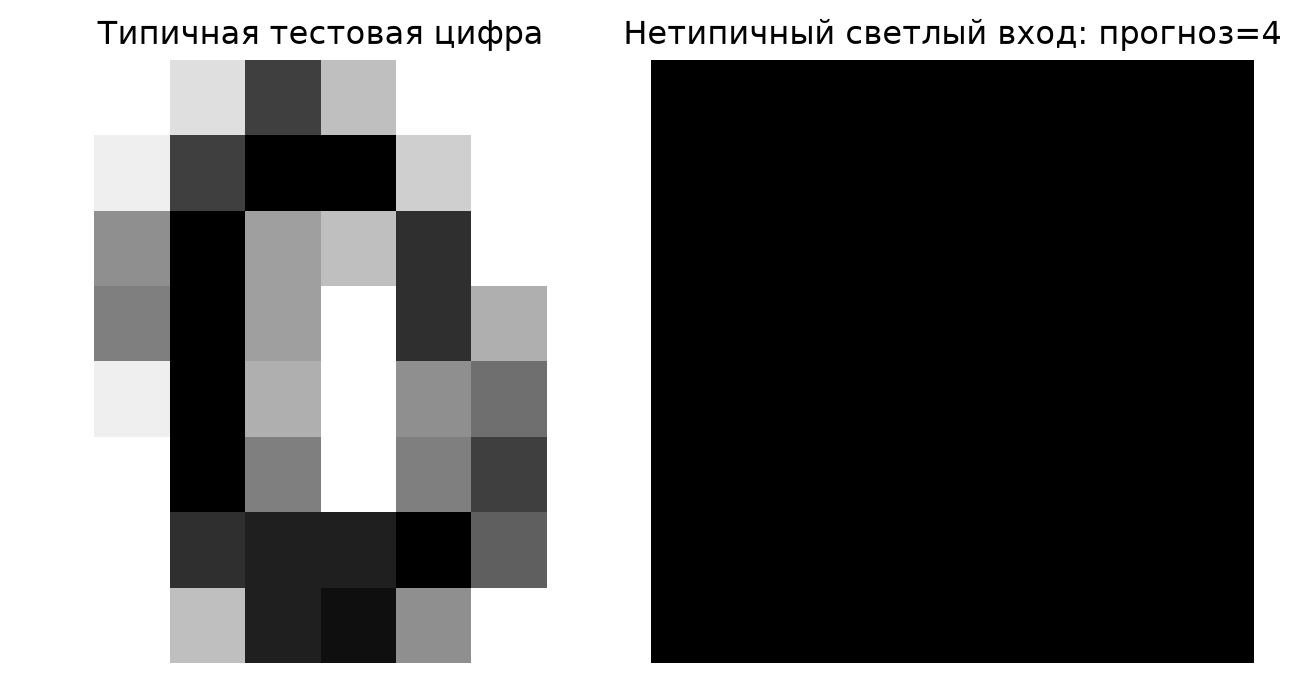

*Рисунок 7 — Полностью светлая матрица как пример нетипичного входа*

In [10]:
outside = robustness["atypical_example"]
print("Прогноз для полностью светлой матрицы:", outside["prediction"])
print("Расстояние до ближайшего обучающего примера:", round(outside["distance_to_nearest_training_example_l2"], 2))
print("95-й процентиль расстояний теста:", round(outside["test_nearest_neighbor_distance_p95_l2"], 2))
print("Выходит за типичный диапазон:", outside["exceeds_typical_test_p95"])
display(Image(filename=str(ROOT / "reports" / "figures" / "lab2_07_atypical_input.png")))
display(Markdown("*Рисунок 7 — Полностью светлая матрица как пример нетипичного входа*"))

## 9. Статический анализ и сохранность программных компонентов

Для проверки Python-модулей `src/` применяется анализатор **Bandit**. Его результат сохраняется в `reports/evidence/lab2_bandit.txt`. Статический анализ выявляет потенциально небезопасные конструкции кода, но не заменяет тестирование входов и проверку качества классификации.

Обучение и предсказание выполняются от пользователя `mluser`. Интерфейс JupyterLab использует адрес `127.0.0.1:8888`, а подключение из Windows организовано через SSH-туннель. Файл модели размещается в каталоге `models/` с ограниченным доступом. Контрольная сумма SHA256 используется для обнаружения изменений артефакта перед его загрузкой; при этом эталон должен сохраняться в доверенном месте. Формат `joblib` применяется только для собственных проверенных моделей.

In [11]:
import importlib.util

if importlib.util.find_spec("bandit") is None:
    print("Пакет Bandit не найден в текущем Python-окружении.")
    print("Команда установки: python -m pip install -r requirements-lab2.txt")
else:
    bandit = subprocess.run(
        [sys.executable, "-m", "bandit", "-r", "src/"],
        cwd=ROOT, capture_output=True, text=True, check=False,
    )
    evidence_dir = ROOT / "reports" / "evidence"
    evidence_dir.mkdir(parents=True, exist_ok=True)
    (evidence_dir / "lab2_bandit.txt").write_text(
        bandit.stdout + bandit.stderr, encoding="utf-8"
    )
    if bandit.returncode != 0:
        print(bandit.stdout)
        print(bandit.stderr)
        raise AssertionError("Статический анализ выявил проблемы, требующие рассмотрения")
    print("Статический анализ Bandit выполнен успешно.")
    print("Результат: потенциально опасных конструкций не обнаружено.")
    print("Протокол: reports/evidence/lab2_bandit.txt")

Статический анализ Bandit выполнен успешно.
Результат: потенциально опасных конструкций не обнаружено.
Протокол: reports/evidence/lab2_bandit.txt


## 10. Сохранение модели и контроль воспроизводимости

В файл `models/digits_baseline.joblib` сохраняется обученный конвейер, включающий масштабирование и классификатор. Основная метрика и идентификатор версии данных записаны в `metrics/baseline.json`, параметры обучения — в `metrics/training_config.json`, контрольная сумма модели — в `integrity/model.sha256`.

Завершающая проверка включает повторное вычисление SHA256, загрузку сохранённого конвейера и предсказание для корректного изображения через общий интерфейс `predict_digits`. Это подтверждает пригодность сохранённого артефакта для последующего использования.

In [12]:
from src.verify import main as verify_all

with redirect_stdout(StringIO()):
    verify_all()
print("Проверка контрольных сумм данных и модели: успешно")
print("Повторная загрузка модели и предсказание: успешно")
print("Файл метрик базовой модели:", (ROOT / "metrics" / "baseline.json"))
print("Контрольная сумма модели:", (ROOT / "integrity" / "model.sha256").read_text(encoding="ascii").strip())

Проверка контрольных сумм данных и модели: успешно
Повторная загрузка модели и предсказание: успешно
Файл метрик базовой модели: /home/mluser/ml-project/metrics/baseline.json
Контрольная сумма модели: 655ada9ced68462b56dc298ad18bba5e2c2b4fe9783181aef8067ffd3467c9a9  models/digits_baseline.joblib


## Заключение

В ходе лабораторной работы обучен базовый классификатор рукописных цифр на **1740 изображениях**. Разделение выполнено со стратификацией и фиксированным случайным состоянием; преобразования признаков обучались только на тренировочной выборке. На **348 тестовых изображениях** получена точность **97,41 % (339 правильных ответов из 348)** при **Macro-F1 ≈ 0,9740**. Простой классификатор наиболее частого класса показал точность **9,77 %**.

Реализована единая функция предсказания с контролем типов, формы, диапазона интенсивностей и размера пакета. Автоматизированное тестирование прошло успешно (**33 теста**). Статический анализ Bandit не обнаружил проблем в проверенных модулях `src/`.

На выборке из 20 изображений слабый шум изменил **2 из 20 ответов (10 %)**, а повышение яркости — **3 из 20 (15 %)**. При этом точность составила соответственно **85 %** и **90 %** против **85 %** на тех же исходных изображениях. Нетипичная полностью светлая матрица была формально принята классификатором; её расстояние до ближайшего обучающего изображения (**91,66**) значительно превысило 95-й процентиль для тестовых объектов (**24,08**).

**Итог:** базовая модель обеспечивает высокое качество на выбранном наборе, однако её ответы чувствительны к некоторым допустимым изменениям входа. Проверка структуры данных не заменяет оценку принадлежности обучающему распределению. Перспективное улучшение — разработка механизма отклонения нетипичных входов на основе отдельной валидационной выборки.